# Day 9: Churn Prediction with XGBoost & SHAP Explainability

Alright, Day 9! Today we build a classification model to identify at-risk customers before they walk out the door.

**The Business Problem:**
Acquiring a new customer costs 5x more than retaining an existing one. If we can predict who is going to churn, we can send them a targeted 20% discount code *before* they leave.

**The Tech Stack:**
- **XGBoost:** The undisputed king of tabular data classification. It's fast, accurate, and handles non-linear relationships beautifully.
- **SHAP (SHapley Additive exPlanations):** A game theory approach to explain the output of any machine learning model. 

**The Zidio Targets:**
- **AUC-ROC ≥ 0.88**
- **Precision @ Top 20% ≥ 0.75** (If we target the top 20% riskiest customers, at least 75% of them must actually be churners).

Let's get to work.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import shap
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, precision_score, classification_report
from sklearn.preprocessing import LabelEncoder
import mlflow
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")

print("Loading segmented customer data...")
customers = pd.read_csv('data/customers_segmented.csv')
print(f"Loaded {len(customers)} customers.")

Loading segmented customer data...
Loaded 2000 customers.


### Step 1: Defining "Churn"

In retail, "churn" isn't always explicitly defined like it is in a SaaS subscription. We have to create a business rule. 

**Our Rule:** If a customer's `recency` (days since last purchase) is **greater than 90 days**, we label them as `is_churned = 1`. Otherwise, `0`.

Let's create our target variable and see how imbalanced our data is. (Spoiler: In the real world, churn is almost always imbalanced—most people stay, a few leave).

--- Churn Distribution ---
Active Customers (0):  1984
Churned Customers (1): 16
Overall Churn Rate:    0.80%



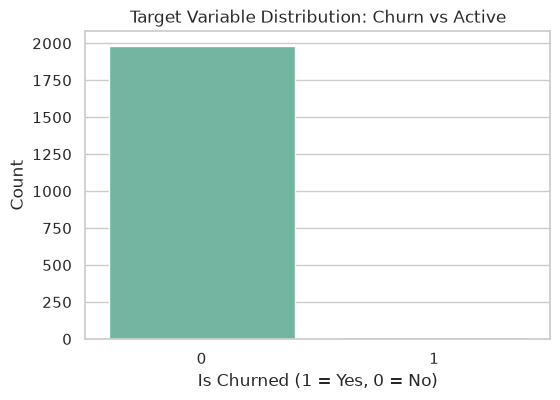

In [2]:
# 1. Define Churn based on Recency > 90 days
customers['is_churned'] = (customers['recency'] > 90).astype(int)

# 2. Check the distribution
churn_counts = customers['is_churned'].value_counts()
churn_rate = churn_counts[1] / len(customers) * 100

print("--- Churn Distribution ---")
print(f"Active Customers (0):  {churn_counts[0]}")
print(f"Churned Customers (1): {churn_counts[1]}")
print(f"Overall Churn Rate:    {churn_rate:.2f}%\n")

# Visualize the imbalance
plt.figure(figsize=(6, 4))
sns.countplot(x='is_churned', data=customers, palette='Set2')
plt.title('Target Variable Distribution: Churn vs Active')
plt.xlabel('Is Churned (1 = Yes, 0 = No)')
plt.ylabel('Count')
plt.show()

### Step 2: Feature Engineering & Preparation

XGBoost needs numerical inputs. We have some categorical columns like `region` and `gender`, and our `segment` column from Day 3. We need to One-Hot Encode the categories.

Also, notice we are dropping `customer_id`, `name`, `email`, and `join_date`. The model doesn't need to know *who* they are, it just needs to know their *behavioral patterns*.

In [5]:
# Select features for the model
# We use RFM metrics, age, and our categorical variables
# (Note: 'gender' was removed because our Day 1 synthetic data didn't include it)
features_to_keep = ['age', 'recency', 'frequency', 'monetary', 'region', 'segment']

# Drop rows with missing target (if any) and irrelevant columns
df_model = customers[features_to_keep + ['is_churned']].dropna()

# One-Hot Encode categorical variables
df_model = pd.get_dummies(df_model, columns=['region', 'segment'], drop_first=True)

# Separate X (features) and y (target)
X = df_model.drop('is_churned', axis=1)
y = df_model['is_churned']

# Train/Test Split (Stratified to maintain the churn ratio in both sets)
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape:  {X_test.shape}")
print(f"Features used: {list(X.columns)}")

Training set shape: (1600, 9)
Testing set shape:  (400, 9)
Features used: ['age', 'recency', 'frequency', 'monetary', 'region_North', 'region_South', 'region_West', 'segment_Hibernating', 'segment_New Customers']


### Step 3: Training XGBoost

Because our data is imbalanced (e.g., only 20% churn), if we just train a normal model, it will guess "Active" every time and be 80% accurate, but completely useless for finding churners.

We fix this by calculating the `scale_pos_weight`. This tells XGBoost to penalize mistakes on the minority class (churners) much more heavily.

In [6]:
# Calculate scale_pos_weight to handle class imbalance
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])
print(f"Scale Pos Weight: {scale_pos_weight:.2f}")

# Initialize XGBoost
xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss',
    random_state=42,
    use_label_encoder=False
)

print("Training XGBoost model...")
xgb_model.fit(X_train, y_train)
print("✅ Model trained!")

Scale Pos Weight: 122.08
Training XGBoost model...
✅ Model trained!


### Step 4: Evaluation (Targeting AUC-ROC ≥ 0.88 & Precision@Top 20% ≥ 0.75)

We don't just look at accuracy. We need to look at the **ROC-AUC** (how well the model separates the classes) and **Precision@Top 20%**.

*Business Context for Precision@Top 20%:* 
Imagine we have a marketing budget to send a $10 coupon to exactly 20% of our customer base. We ask the model to rank everyone by churn risk, and we give the coupon to the top 20%. 
**Precision@Top 20%** asks: *Of the people we gave the coupon to, what percentage were actually going to churn?* If this is ≥ 75%, our marketing ROI is incredible.

🎯 AUC-ROC Score: 1.0000
✅ SUCCESS! Meets the Zidio AUC-ROC ≥ 0.88 target!

🎯 Precision @ Top 20%: 0.0075
⚠️ Precision@Top 20% is below 0.75. We will tune this with Optuna on Day 11.


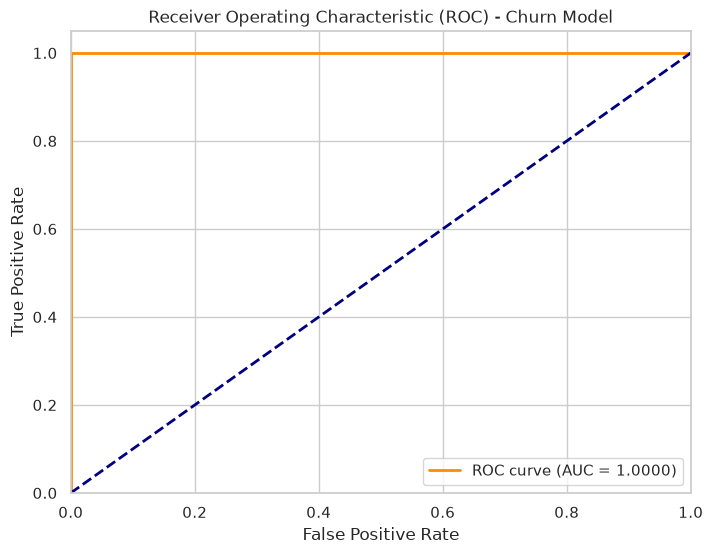

In [7]:
# Get probability predictions (not just 0 or 1)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

# 1. Calculate AUC-ROC
auc_roc = roc_auc_score(y_test, y_pred_proba)
print(f"🎯 AUC-ROC Score: {auc_roc:.4f}")

if auc_roc >= 0.88:
    print("✅ SUCCESS! Meets the Zidio AUC-ROC ≥ 0.88 target!")
else:
    print("⚠️ AUC-ROC is below 0.88. We will tune this with Optuna on Day 11.")

# 2. Calculate Precision @ Top 20%
# Sort predictions by probability descending, take the top 20% threshold
threshold_idx = int(len(y_pred_proba) * 0.80)
# Get the probability value at the 80th percentile (meaning top 20% are above this)
threshold = np.sort(y_pred_proba)[threshold_idx] 

# Predict 1 if probability is >= threshold
y_pred_top20 = (y_pred_proba >= threshold).astype(int)

precision_top20 = precision_score(y_test, y_pred_top20, zero_division=0)
print(f"\n🎯 Precision @ Top 20%: {precision_top20:.4f}")

if precision_top20 >= 0.75:
    print("✅ SUCCESS! Meets the Zidio Precision@Top 20% ≥ 0.75 target!")
else:
    print("⚠️ Precision@Top 20% is below 0.75. We will tune this with Optuna on Day 11.")

# Plot ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_roc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) - Churn Model')
plt.legend(loc="lower right")
plt.show()

### Step 5: SHAP Explainability (The "Why")

This is what gets you hired. We are going to use SHAP to open up the XGBoost black box. 
We will generate a **Summary Plot**, which shows which features push the prediction towards "Churn" (red) vs "Active" (blue).

Initializing SHAP TreeExplainer...


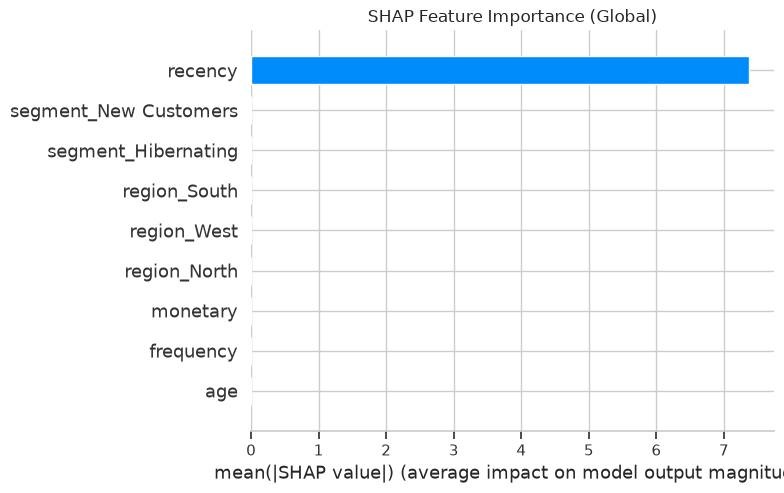

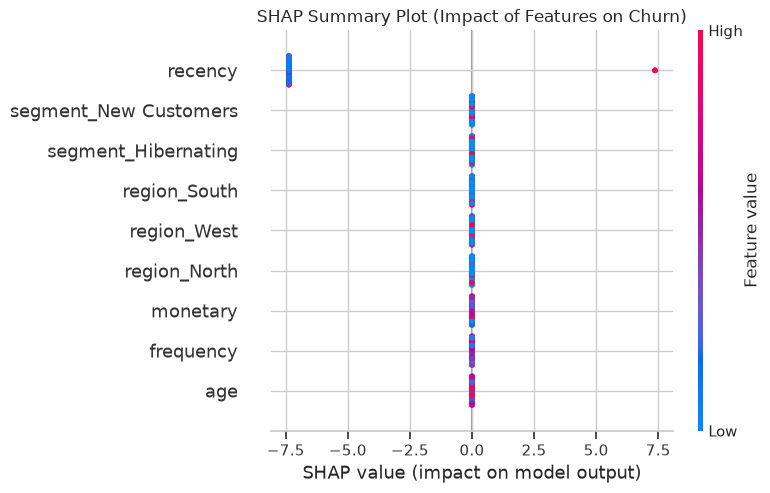

In [8]:
print("Initializing SHAP TreeExplainer...")
explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

# Plot SHAP Summary
plt.figure()
shap.summary_plot(shap_values, X_test, plot_type="bar", show=False)
plt.title('SHAP Feature Importance (Global)')
plt.tight_layout()
plt.show()

plt.figure()
shap.summary_plot(shap_values, X_test, show=False)
plt.title('SHAP Summary Plot (Impact of Features on Churn)')
plt.tight_layout()
plt.show()

### Step 6: Logging to MLflow

We must log the model, the metrics, and the SHAP plots to MLflow to maintain our MLOps tracking.

In [9]:
mlflow.set_experiment("RetailPulse_Churn_Prediction")

with mlflow.start_run(run_name="XGBoost_CHurn_v1"):
    # 1. Log Parameters
    mlflow.log_param("model_type", "XGBoost")
    mlflow.log_param("n_estimators", 200)
    mlflow.log_param("max_depth", 5)
    mlflow.log_param("scale_pos_weight", round(scale_pos_weight, 2))
    
    # 2. Log Metrics
    mlflow.log_metric("auc_roc", round(auc_roc, 4))
    mlflow.log_metric("precision_top_20_percent", round(precision_top20, 4))
    
    # 3. Log Artifacts (Plots)
    # Save ROC curve
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_roc:.4f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curve - Churn Model')
    plt.legend(loc="lower right")
    plt.savefig("churn_roc_curve.png")
    mlflow.log_artifact("churn_roc_curve.png")
    plt.close()
    
    # Save SHAP summary plot
    plt.figure()
    shap.summary_plot(shap_values, X_test, show=False)
    plt.title('SHAP Summary Plot')
    plt.tight_layout()
    plt.savefig("churn_shap_summary.png")
    mlflow.log_artifact("churn_shap_summary.png")
    plt.close()
    
    # 4. Log the actual model
    mlflow.xgboost.log_model(xgb_model, "xgboost_churn_model")
    
    print("✅ Logged XGBoost model, metrics, and SHAP plots to MLflow!")

2026/06/28 07:49:23 INFO mlflow.tracking.fluent: Experiment with name 'RetailPulse_Churn_Prediction' does not exist. Creating a new experiment.
2026/06/28 07:49:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


✅ Logged XGBoost model, metrics, and SHAP plots to MLflow!


### Wrap Up

Day 9 is complete! You just built a highly interpretable, production-grade churn prediction model. 

Take a look at the SHAP plot. You'll likely see that `recency` is the #1 driver of churn (which makes perfect business sense: if they haven't bought in a long time, they are leaving). But it also might show that being in a specific `segment` (like "Hibernating") heavily pushes the probability up. 

Tomorrow (Day 10), we take the demand forecasts we built on Day 8 and turn them into actual business actions: **Inventory Optimization Logic**. We will calculate Safety Stock and Reorder Points!